In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import yaml
import numpy as np
import os
from PIL import Image
import glob
%matplotlib inline

In [2]:
MAP_NAME = "e7_fifth_big_raceline"

# The original, un-massaged map (NOT closed into a loop) to overlay the raceline on in the
# "OPTIONAL Overlay on the original map" section below. It has its own maps/<name>.yaml + .pgm.
ORIG_MAP_NAME = "e7_fifth_big_real"

In [3]:
csv_files = glob.glob(f'outputs/{MAP_NAME}/*.csv', recursive=True)
csv_files = sorted(csv_files)
csv_files

['outputs/e7_fifth_big_raceline/traj_race_cl-2026-07-14 20:18:01.873872.csv',
 'outputs/e7_fifth_big_raceline/traj_race_cl-2026-07-20 18:26:01.353739.csv']

In [4]:
raw_data = pd.read_csv(csv_files[-1], header=None, sep=',')
raw_data

,0,1,2
0,0.668048,3.235525,2.563221
1,0.641566,3.092697,2.569275
2,0.622113,2.946895,2.575329
3,0.609685,2.798733,2.581383
4,0.604273,2.648823,2.587438
...,...,...,...
356,0.861178,3.813042,2.503539
357,0.801593,3.675488,2.503539
358,0.749327,3.533292,2.503539
359,0.704704,3.386592,2.503539


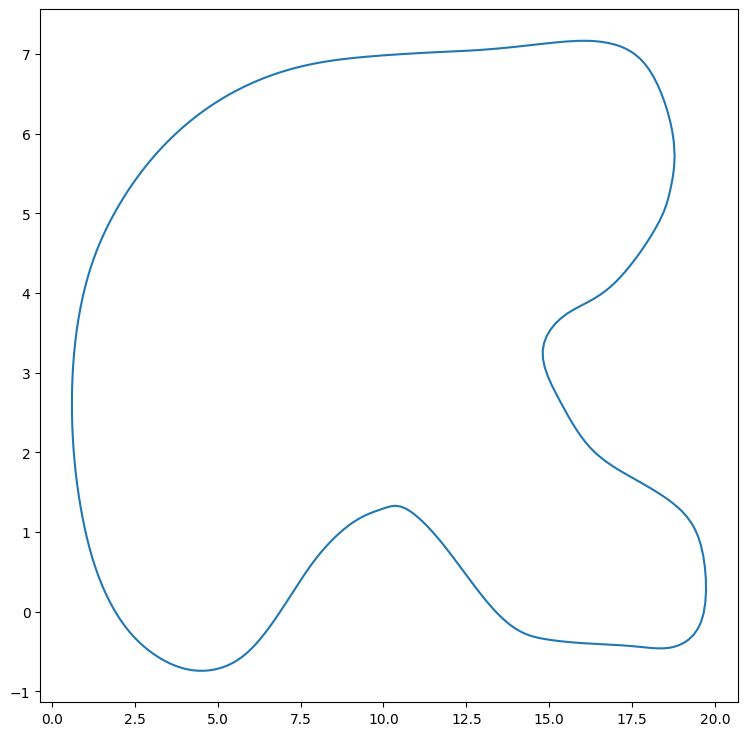

In [5]:
plt.figure(figsize=(9,9))
plt.plot(raw_data.iloc[:, 0], raw_data.iloc[:, 1])

In [6]:
# Overlay the racetrack on the map
# load map yaml
if os.path.exists(f"maps/{MAP_NAME}.png"):
    map_img_path = f"maps/{MAP_NAME}.png"
elif os.path.exists(f"maps/{MAP_NAME}.pgm"):
    map_img_path = f"maps/{MAP_NAME}.pgm"
else:
    raise Exception("Map not found!")

map_yaml_path = f"maps/{MAP_NAME}.yaml"
with open(map_yaml_path, 'r') as yaml_stream:
    try:
        map_metadata = yaml.safe_load(yaml_stream)
        map_resolution = map_metadata['resolution']
        origin = map_metadata['origin']
    except yaml.YAMLError as ex:
        print(ex)

# calculate map parameters
orig_x = origin[0]
orig_y = origin[1]
# ??? Should be 0
orig_s = np.sin(origin[2])
orig_c = np.cos(origin[2])

# get the distance transform
transformed_data = raw_data.copy()
transformed_data -= np.array([orig_x, orig_y, 0])
transformed_data.iloc[:, :2] /= map_resolution

raw_map_img = np.array(Image.open(map_img_path).transpose(Image.FLIP_TOP_BOTTOM))
raw_map_img = raw_map_img.astype(np.float64)


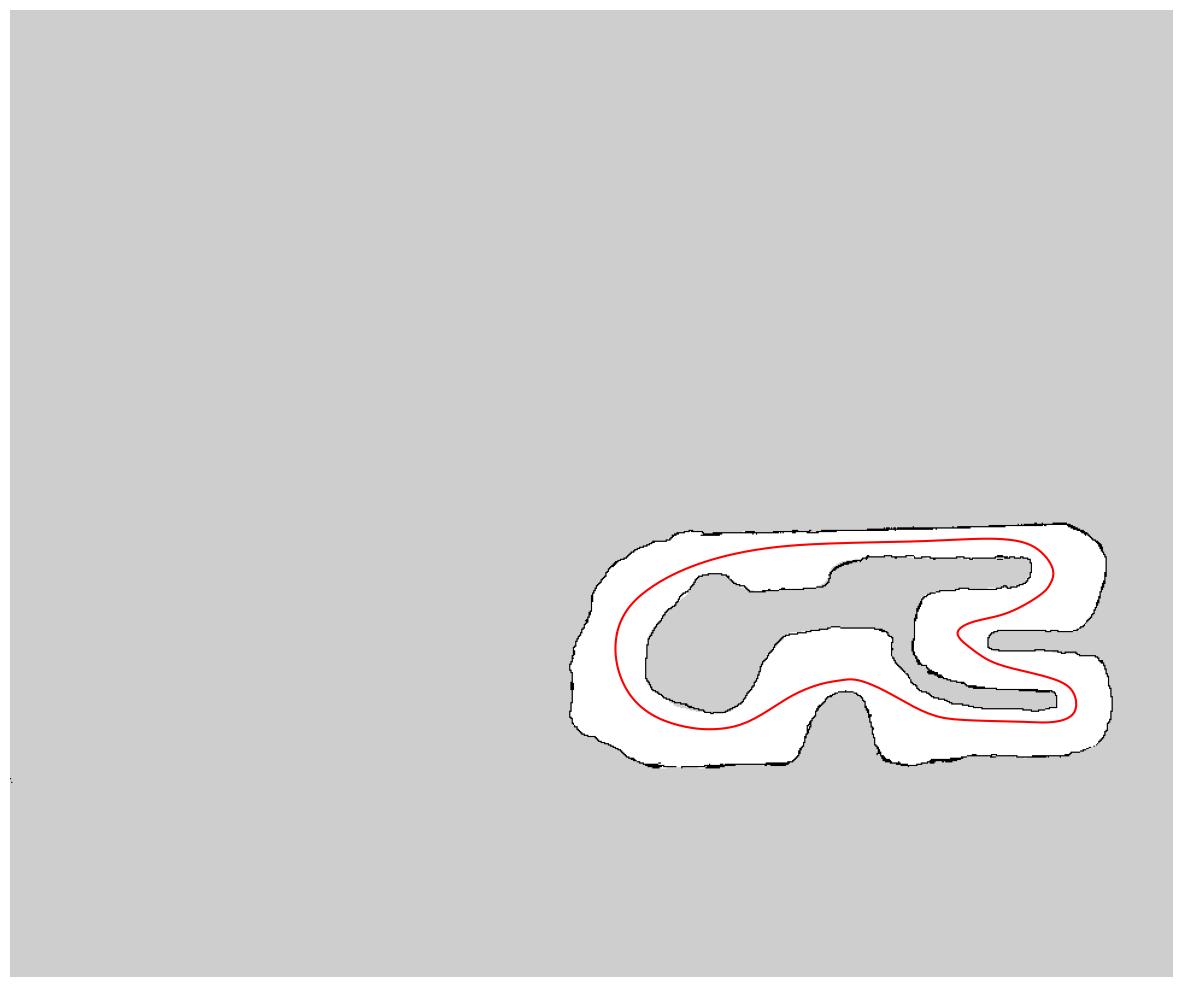

In [7]:
plt.figure(figsize=(15,15))
plt.imshow(raw_map_img, cmap='gray', origin='lower')
plt.plot(transformed_data.iloc[:, 0], transformed_data.iloc[:, 1], color='red')
# Save image without the axis
plt.axis('off')
plt.savefig(f"outputs/{MAP_NAME}_raceline.png", bbox_inches='tight', pad_inches=0)

(-0.5, 964.5, -0.5, 802.5)

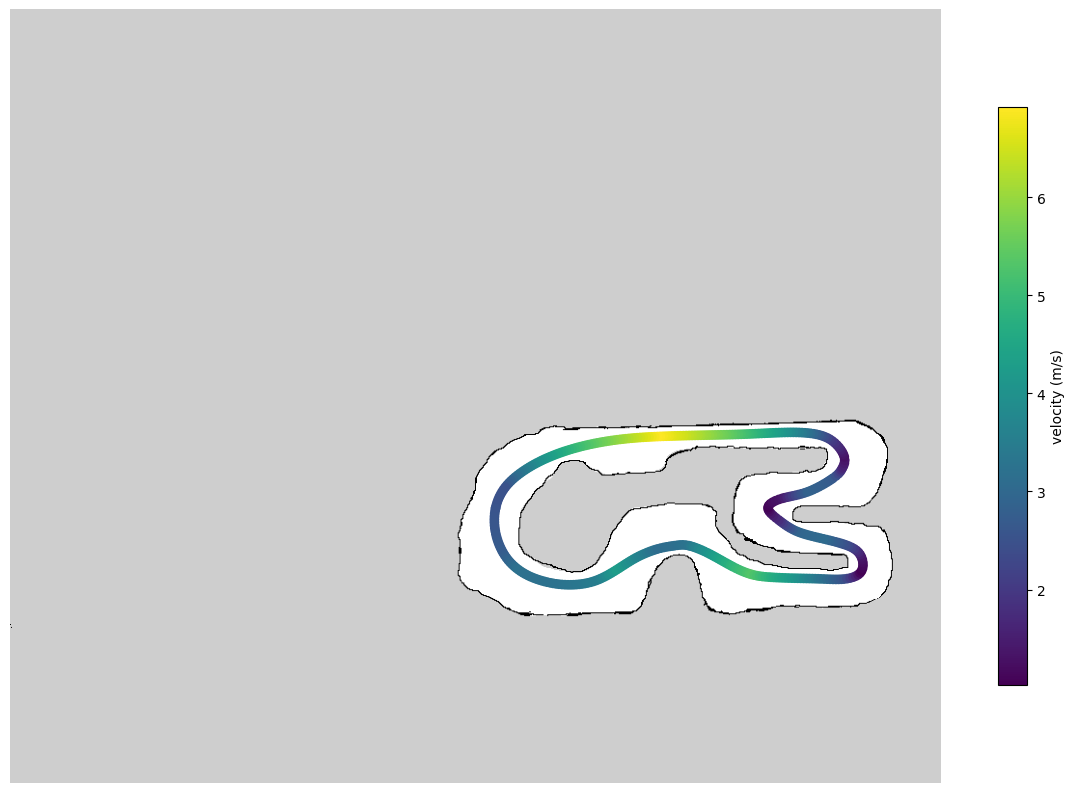

In [8]:
%matplotlib inline
plt.figure(figsize=(15,15))
plt.scatter(transformed_data.iloc[:, 0], transformed_data.iloc[:, 1], c=transformed_data.iloc[:, 2])
cbar = plt.colorbar(shrink=0.5)
cbar.set_label('velocity (m/s)')

plt.imshow(raw_map_img, cmap='gray', origin='lower')
plt.axis('off')

## (OPTIONAL) Overlay on the original map

Overlays the raceline on `ORIG_MAP_NAME` (the real, un-massaged map). The pixel transform is
recomputed from that map's own yaml (origin + resolution), so it stays correct even if the
original map's frame differs from the raceline map's.

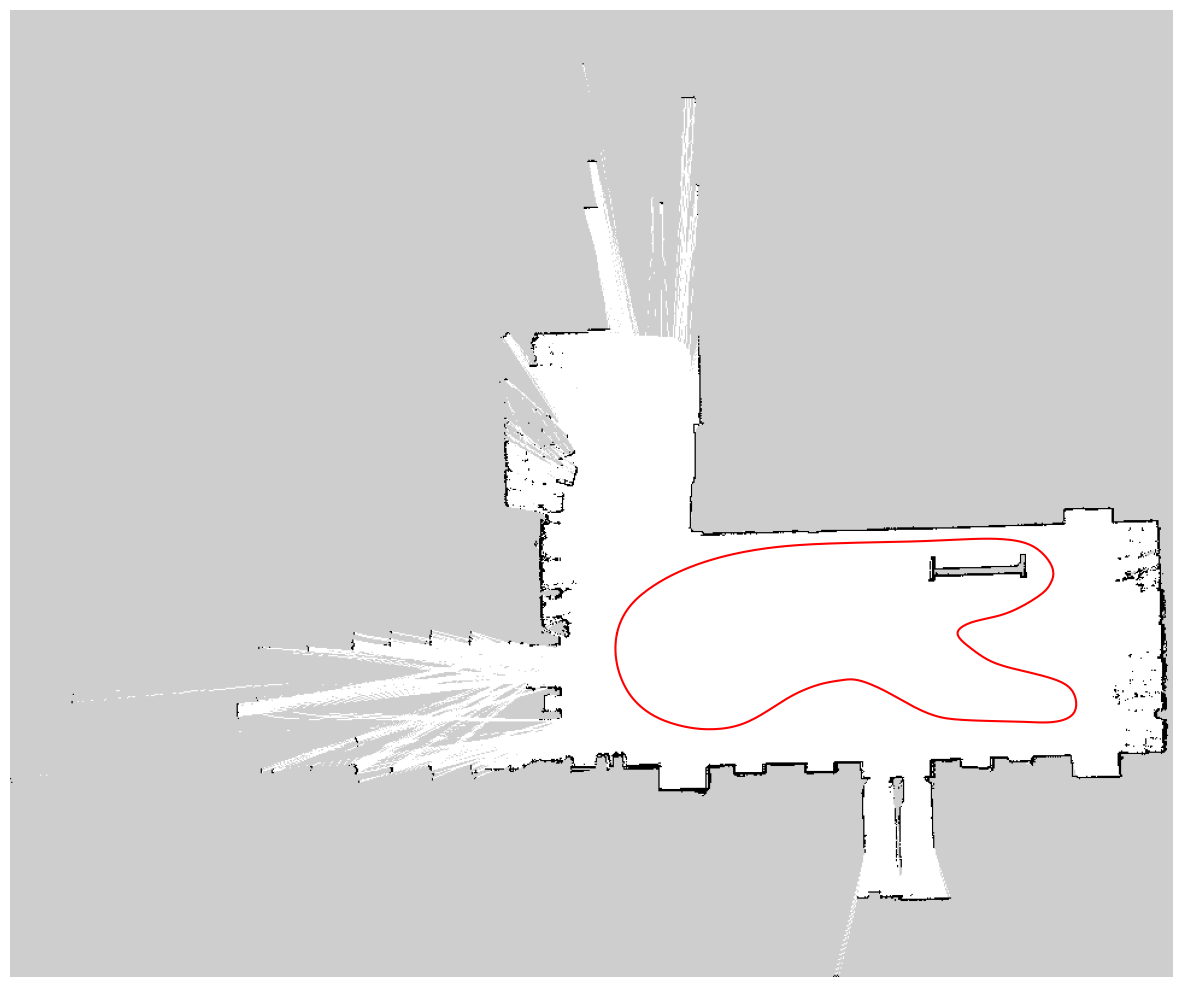

In [9]:
# Convert the raceline (raw_data, in meters) into the ORIGINAL map's pixel frame using that
# map's own yaml, then overlay.
orig_yaml_path = f"maps/{ORIG_MAP_NAME}.yaml"
with open(orig_yaml_path, 'r') as yaml_stream:
    orig_meta = yaml.safe_load(yaml_stream)
orig_res = orig_meta['resolution']
orig_origin = orig_meta['origin']

# meters -> pixels in the original map frame (raw_data columns: x_m, y_m, velocity)
orig_overlay = raw_data.copy()
orig_overlay -= np.array([orig_origin[0], orig_origin[1], 0])
orig_overlay.iloc[:, :2] /= orig_res

orig_map_img = np.array(Image.open(f"maps/{ORIG_MAP_NAME}.pgm").transpose(Image.FLIP_TOP_BOTTOM))
orig_map_img = orig_map_img.astype(np.float64)

plt.figure(figsize=(15, 15))
plt.imshow(orig_map_img, cmap='gray', origin='lower')
plt.plot(orig_overlay.iloc[:, 0], orig_overlay.iloc[:, 1], color='red')
plt.axis('off')
plt.savefig(f"outputs/{MAP_NAME}_raceline_on_{ORIG_MAP_NAME}.png", bbox_inches='tight', pad_inches=0)

(-0.5, 964.5, -0.5, 802.5)

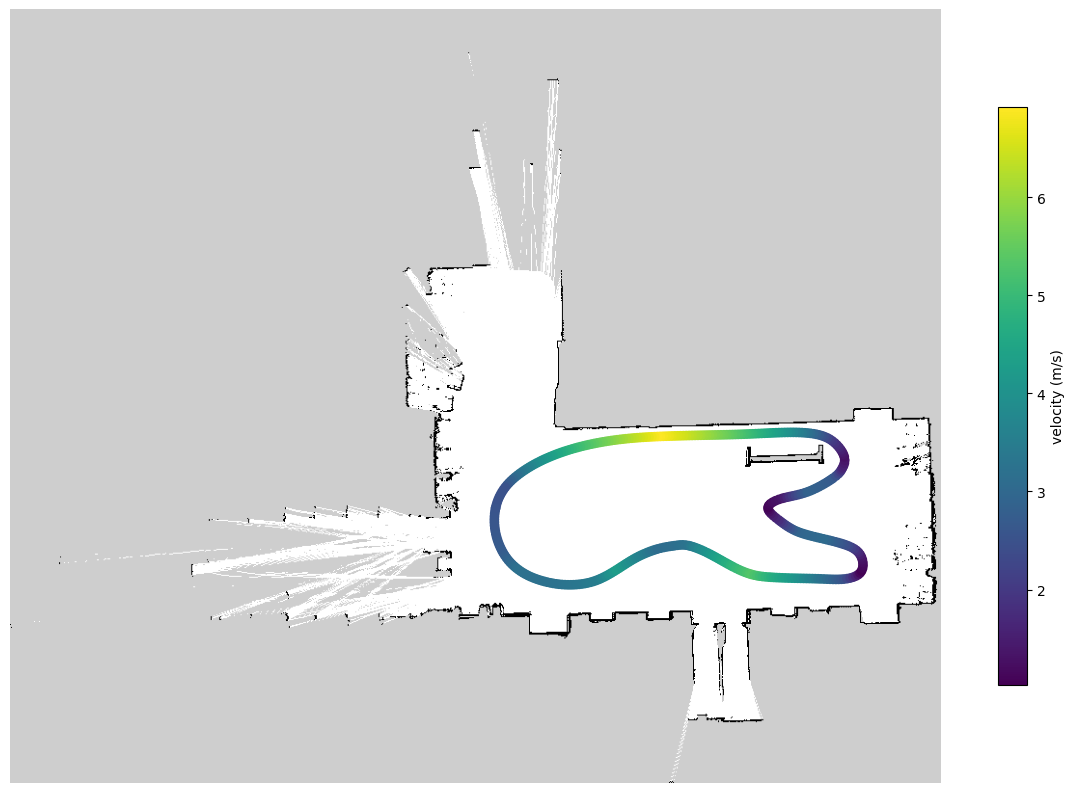

In [10]:
plt.figure(figsize=(15, 15))
plt.imshow(orig_map_img, cmap='gray', origin='lower')
plt.scatter(orig_overlay.iloc[:, 0], orig_overlay.iloc[:, 1], c=orig_overlay.iloc[:, 2])
cbar = plt.colorbar(shrink=0.5)
cbar.set_label('velocity (m/s)')
plt.axis('off')

## Visualize Velocity Profile in 3D

In [11]:
raw_data_np = transformed_data.to_numpy()

In [12]:
from mpl_toolkits.mplot3d import Axes3D
%matplotlib qt
# Visualize Velocity Profile
scale_x = 1.0
scale_y = 1.0
scale_z = 0.3  # scale z axis such that it does not appear stretched

# create 3d plot

fig = plt.figure(figsize=(15, 15))
ax = fig.gca(projection='3d')

# recast get_proj function to use scaling factors for the axes
ax.get_proj = lambda: np.dot(Axes3D.get_proj(ax), np.diag([scale_x, scale_y, scale_z, 1.0]))

ax.grid()
ax.set_aspect("auto")
ax.set_xlabel("east in m")
ax.set_ylabel("north in m")

# Doesn't work
# import matplotlib
# x,y = np.mgrid[0:orig_map_img.shape[0], 0:orig_map_img.shape[1]]
# ax.plot_surface(x,y,np.sin(0*x), facecolors=matplotlib.cm.ScalarMappable(cmap='gray').to_rgba(orig_map_img))

# plot velocity profile in 3D
ax.plot(raw_data_np[:, 0], raw_data_np[:, 1], raw_data_np[:, 2], color="k")
ax.set_zlabel("velocity in m/s")

# plot vertical lines visualizing acceleration and deceleration zones
ind_stepsize = 1
cur_ind = 0
no_points_traj_vdc = np.shape(raw_data_np)[0]
prev_vel = 0
curr_vel = 0

while cur_ind < no_points_traj_vdc - 1:
	curr_vel = raw_data_np[cur_ind, 2]
	x_tmp = [raw_data_np[cur_ind, 0], raw_data_np[cur_ind, 0]]
	y_tmp = [raw_data_np[cur_ind, 1], raw_data_np[cur_ind, 1]]
	z_tmp = [0.0, curr_vel]  # plot line with height depending on velocity

	# get proper color for line depending on acceleration
	if curr_vel - prev_vel > 0.0:
		col = "g"
	elif curr_vel - prev_vel < 0.0:
		col = "r"
	else:
		col = "gray"
	
	prev_vel = curr_vel

	# plot line
	ax.plot(x_tmp, y_tmp, z_tmp, color=col)

	# increment index
	cur_ind += ind_stepsize


plt.show()

ImportError: Failed to import any qt binding